# Column scaling for LSsurf's CHOLMOD solve

LSsurf can solve each `smooth_fit` iteration's least-squares problem with CHOLMOD (a Cholesky factorization of the normal equations, followed by iterative refinement) instead of SPQR (a sparse QR factorization).  Before it trusts a CHOLMOD solve, `LSsurf/ls_solvers.py` checks CHOLMOD's condition estimate `rcond` and falls back to SPQR when `rcond < RCOND_MIN = 1e-14`.

On dense north-Greenland tiles that check rejected solves that were accurate to $10^{-8}$ m, and made CHOLMOD slower than SPQR alone.  This notebook explains why, and why factoring the column-scaled normal matrix

$$\tilde N = D A^T A D,\qquad D = \mathrm{diag}\left(1/\|a_j\|\right)$$

(option `scale_columns` in `ls_solvers`, `cholmod_scale_columns` in `smooth_fit`, `--cholmod_scale_columns` in `fit_altimetry.py`) fixes the check without changing the solution.

**Summary**

1. CHOLMOD's `rcond` is $(\min_j L_{jj} / \max_j L_{jj})^2$, where $L$ is the Cholesky factor.
2. Each pivot is a column norm times an angle: $L_{jj} = \|\tilde a_j\| \sin\phi_j$, where $\phi_j$ is the angle between the $j$-th column (in the fill-reducing order) and the span of the columns before it.
3. Scaling makes every column norm 1, so $\mathrm{rcond}(\tilde N) = \min_j \sin^2\phi_j$: only near-dependence between columns is left.  The units and weights of the unknowns drop out.
4. The scaled problem has the same solution, the same sparsity, the same ordering and the same cost (about 1% extra), and Cholesky's accuracy is governed by the scaled matrix either way.
5. `rcond` is one-sided ($\mathrm{rcond} \ge 1/\kappa_2(A^TA)$), so the refinement-convergence check is still what guarantees accuracy.
6. On the first E210_N-680 system the column norms span 6.3 decades.  Unscaled `rcond` is $1.2\times10^{-14}$ (just above the limit; other iterations fell below it); scaled, it is $1.1\times10^{-5}$.  On the production runs every iteration stayed on CHOLMOD, at 8–10 s per iteration against 35–46 s for SPQR, matching SPQR to about $10^{-10}$ m.

In [1]:
import os, sys, warnings
import numpy as np
import scipy.sparse as sp
import pandas as pd
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
from sksparse.cholmod import CholeskyFactor
import LSsurf.ls_solvers as ls

threadpool_limits(limits=4)

# synthetic test problems from LSsurf/tests/test_ls_solvers.py
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..', 'tests')))
from test_ls_solvers import random_ls, collinear_ls, rel_diff

def factor(N, order='metis'):
    # CHOLMOD LL' factor of N; CHOLMOD's "nearly singular" warnings silenced
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        F = CholeskyFactor(N, order=order)
        F.factorize(N)
    return F

def unit_diagonal(N):
    # D N D with D = diag(1/sqrt(N_jj)), done as LSsurf.ls_solvers does it; returns (D N D, d)
    N_jj = N.diagonal()
    d = 1. / np.sqrt(np.where(N_jj > 0, N_jj, 1.))
    Ns = N.tocsc(copy=True)
    Ns.data *= d[Ns.indices]
    Ns.data *= np.repeat(d, np.diff(Ns.indptr))
    return Ns, d

def normal(A):
    A = A.tocsc()
    return (A.T @ A).tocsc()

## 1. The two solvers

Each iteration solves $\min_x \|Ax - b\|_2$.  The rows of $A$ are data and constraint equations, each divided by its expected error; the columns are the unknowns ($z_0$ and $dz$ grid nodes, biases, and so on).

* **SPQR** factors $AP = QR$ and solves $x = P R^{-1} Q^T b$.  Its accuracy depends on $\kappa_2(A)$.
* **CHOLMOD** forms $N = A^T A$, factors $P^T N P = L L^T$ with a METIS fill-reducing permutation $P$, solves $N x = A^T b$, and then refines up to three times, $x \leftarrow x + N^{-1} A^T (b - Ax)$.  It falls back to SPQR if `rcond < 1e-14` before solving, or if the last refinement step is still $\ge 10^{-6}$ of $\|x\|$.

The normal equations square the condition number, $\kappa_2(N) = \kappa_2(A)^2$.  That is why refinement is needed.  It is also why a condition estimate on $N$ looks alarming.

## 2. What CHOLMOD's `rcond` is

CHOLMOD's `cholmod_rcond` is not a condition-number estimate in the LAPACK sense.  It is a free by-product of the factorization: the ratio of the smallest to the largest diagonal entry of $L$, squared for an $LL^T$ factor,

$$\mathrm{rcond} = \left(\frac{\min_j L_{jj}}{\max_j L_{jj}}\right)^2 .$$

Checking that on a small problem, together with $LL^T = P^T N P$:

In [2]:
A, b = random_ls(scale_decades=3)
N = normal(A)
F = factor(N)
p = np.asarray(F.perm)
L = F.L
L_jj = L.diagonal()
print(f"CHOLMOD rcond             {F.rcond:.6e}")
print(f"(min L_jj / max L_jj)^2   {(L_jj.min() / L_jj.max())**2:.6e}")
print(f"max |L L' - P'N P| / max |N|  {abs(L @ L.T - N[p][:, p]).max() / abs(N).max():.1e}")

CHOLMOD rcond             8.220678e-07
(min L_jj / max L_jj)^2   8.220678e-07
max |L L' - P'N P| / max |N|  2.4e-16


## 3. What the pivots $L_{jj}$ measure

Let $\tilde a_j$ be the $j$-th column of $AP$, the columns in the order CHOLMOD factors them.  If $AP = QR$, then $P^T A^T A P = R^T Q^T Q R = R^T R$.  Cholesky factors with a positive diagonal are unique, so $L = R^T$ up to the signs of the rows of $R$, and $L_{jj} = |R_{jj}|$.

In Gram–Schmidt terms, $|R_{jj}|$ is the part of $\tilde a_j$ that is not already in the span of the columns before it:

$$L_{jj} = |R_{jj}| = \mathrm{dist}\left(\tilde a_j,\ \mathrm{span}\{\tilde a_1, \dots, \tilde a_{j-1}\}\right) = \|\tilde a_j\| \sin\phi_j ,$$

where $\phi_j$ is the angle between $\tilde a_j$ and that span.  So

$$\mathrm{rcond}(A^TA) = \left(\frac{\min_j \|\tilde a_j\| \sin\phi_j}{\max_j \|\tilde a_j\| \sin\phi_j}\right)^2 .$$

Two unrelated things are multiplied together:

* **Column lengths**, $\|\tilde a_j\|$.  These come from the units of each unknown, the weights ($1/\sigma$, $1/E_{RMS}$) of the rows it appears in, and how many rows it appears in.  A track-bias column touches thousands of weighted data rows; a $z_0$ node in a cell with no data is touched only by smoothness constraints.
* **Angles**, $\sin\phi_j$.  These measure actual near-dependence between unknowns.

Only the second says anything about whether the problem is close to singular.  But when column lengths span many decades, the first dominates `rcond`.

Checking $L_{jj} = \|\tilde a_j\|\sin\phi_j$ directly, by projecting each column onto the span of the columns before it:

In [3]:
A, b = random_ls(m=200, n=40, scale_decades=3, seed=1)
F = factor(normal(A))
p = np.asarray(F.perm)
Ap = A[:, p].toarray()
dist = np.empty(Ap.shape[1])
for j in range(Ap.shape[1]):
    a = Ap[:, j]
    if j == 0:
        dist[j] = np.linalg.norm(a)
    else:
        c = np.linalg.lstsq(Ap[:, :j], a, rcond=None)[0]
        dist[j] = np.linalg.norm(a - Ap[:, :j] @ c)
norms = np.linalg.norm(Ap, axis=0)
print(f"max |L_jj - dist(a_j, span of earlier columns)| / L_jj : {np.max(np.abs(F.L.diagonal() - dist) / dist):.1e}")
print(f"column norms span {np.log10(norms.max() / norms.min()):.1f} decades;  sin(phi_j) ranges {np.min(dist / norms):.3f} to {np.max(dist / norms):.3f}")

max |L_jj - dist(a_j, span of earlier columns)| / L_jj : 4.1e-16
column norms span 3.0 decades;  sin(phi_j) ranges 0.830 to 1.000


## 4. Column scaling

Let $D = \mathrm{diag}(d_j)$ with $d_j = 1/\|a_j\|$, and substitute $x = Dy$:

$$\min_y \|A D y - b\|_2 .$$

$D$ is invertible and diagonal, so this is the same problem with each unknown in different units: if $y^\ast$ minimizes it, $x^\ast = D y^\ast$ minimizes the original problem.  Its normal equations are

$$\tilde N y = D A^T b, \qquad \tilde N = D A^T A D = D N D, \qquad \tilde N_{jj} = d_j^2 \|a_j\|^2 = 1 .$$

What changes and what doesn't:

* **Sparsity is unchanged**, so METIS picks the same ordering, and the fill and the flop count are the same.
* **Angles don't depend on column lengths**, so the scaled pivots are $\tilde L_{jj} = \sin\phi_j = L_{jj} / \|\tilde a_j\|$.
* **The first column in the order has nothing before it**, so $\sin\phi_1 = 1$, and every $\sin\phi_j \le 1$.  Therefore $\max_j \tilde L_{jj} = 1$ and

$$\mathrm{rcond}(\tilde N) = \min_j \sin^2\phi_j .$$

The scaled `rcond` asks one question: how close does any column come to lying in the span of the columns factored before it?

**Solving with the scaled factor.** Since $\tilde N^{-1} = D^{-1} N^{-1} D^{-1}$, we have $N^{-1} r = D\, \tilde N^{-1} (D r)$.  `ls_solvers` uses this for the first solve ($r = A^T b$) and for every refinement step ($r = A^T(b - Ax)$).  The refinement residual and the convergence test stay in the original units.

Checking these claims on columns spread over 8 decades (unscaled `rcond` $\approx 10^{-16}$, which falls back):

In [4]:
A, b = random_ls(scale_decades=8)
N = normal(A)
Ns, d = unit_diagonal(N)
F, Fs = factor(N), factor(Ns)
p = np.asarray(F.perm)
print(f"diagonal of D N D: {Ns.diagonal().min():.15f} to {Ns.diagonal().max():.15f}")
print(f"same METIS ordering: {np.array_equal(p, np.asarray(Fs.perm))}")
print(f"max |scaled pivot - L_jj/||a_j|||: {np.max(np.abs(Fs.L.diagonal() - F.L.diagonal() * d[p])):.1e}")
print(f"largest scaled pivot: {Fs.L.diagonal().max():.15f}")
print(f"rcond unscaled {F.rcond:.1e}   scaled {Fs.rcond:.2f}")
x_qr = ls.solve_spqr(A, b)
x_s, info = ls.solve_cholmod(A, b, scale_columns=True)
x_u, info_u = ls.solve_cholmod(A, b)
print(f"scaled cholmod vs SPQR: relative difference {rel_diff(x_s, x_qr):.1e}")
print(f"unscaled cholmod: {info_u['reason']}")

diagonal of D N D: 1.000000000000000 to 1.000000000000000
same METIS ordering: True
max |scaled pivot - L_jj/||a_j|||: 2.2e-16
largest scaled pivot: 1.000000000000000
rcond unscaled 1.2e-16   scaled 0.66
scaled cholmod vs SPQR: relative difference 1.2e-15
unscaled cholmod: A'A numerically singular (rcond 1.2e-16 < 1e-14)


## 5. Why scaling does not change accuracy, and why that matters

Cholesky is essentially invariant under symmetric diagonal scaling.  The recurrences are

$$L_{jj} = \sqrt{N_{jj} - \sum_{k<j} L_{jk}^2}, \qquad L_{ij} = \Big(N_{ij} - \sum_{k<j} L_{ik} L_{jk}\Big) / L_{jj} .$$

Replacing $N$ by $DND$ multiplies every quantity by the matching $d_i d_j$, so the factor of $DND$ is $DL$.  If the $d_j$ are powers of two this holds exactly in floating point (barring overflow and underflow).  For general $d_j$ it holds to rounding.

The error analysis of Cholesky reflects this.  The error in the computed solution is bounded in terms of $\kappa_2(H)$ for the unit-diagonal matrix $H = DND$, not $\kappa_2(N)$ (van der Sluis 1969; Demmel 1989; Higham 2002, ch. 10).  Van der Sluis also showed that this unit-diagonal scaling is within a factor $m$ (the most nonzeros in any row of $N$) of the best possible diagonal scaling, so a cleverer diagonal scaling can't gain much.

So:

* The unscaled CHOLMOD solve was already as accurate as the scaled one.  On E210_N-680 both match SPQR to about $10^{-10}$ m, and the scaled and unscaled solutions agree to $10^{-10}$ m.  Scaling is not needed for accuracy.
* The unscaled `rcond` tested a number inflated by units and weights, $\kappa(N)$.  The scaled `rcond` tests an estimate tied to $\kappa(H)$, the quantity that actually controls accuracy.  The 1e-14 limit only means something when applied to the scaled matrix.

## 6. What `rcond` does and does not guarantee

For every column, in the factorization order,

$$\sigma_{\min}(A) \le \mathrm{dist}(\tilde a_j, \mathrm{span}\{\tilde a_k: k \ne j\}) \le L_{jj} \le \|\tilde a_j\| \le \sigma_{\max}(A).$$

* **First inequality:** the distance is $\min \|A x\|$ over $x$ with $x_j = 1$, and $\|Ax\| \ge \sigma_{\min}\|x\| \ge \sigma_{\min}$.
* **Second:** the columns before $\tilde a_j$ are a subset of all the other columns.
* **Third:** $\sin\phi_j \le 1$.
* **Fourth:** $\|A e_j\| \le \sigma_{\max}$.

Hence

$$\mathrm{rcond} \ge \left(\frac{\sigma_{\min}}{\sigma_{\max}}\right)^2 = \frac{1}{\kappa_2(A^TA)} .$$

A small `rcond` proves the (scaled) problem is ill-conditioned.  A large `rcond` does not prove it is well-conditioned: no single column is close to the span of the columns before it, yet combinations of many columns can still be.  The ratio of a triangular factor's diagonal entries is only a lower bound on its condition number (Higham 2002, ch. 8).

An example with unit-norm columns, where $A^TA$ is singular to working precision:

In [5]:
n, alpha = 60, 0.5
T = np.eye(n) - alpha * np.triu(np.ones((n, n)), 1)    # each column leans on all earlier ones
T /= np.linalg.norm(T, axis=0)                          # unit-norm columns
rng = np.random.default_rng(0)
Q, _ = np.linalg.qr(rng.standard_normal((3 * n, n)))
A = sp.csc_matrix(Q @ T); b = rng.standard_normal(3 * n)
N = normal(A)
print(f"cond(A'A) = {np.linalg.cond(N.toarray()):.1e}   (1/cond = {1 / np.linalg.cond(N.toarray()):.0e})")
print(f"rcond, natural order: {factor(N, order='natural').rcond:.2f}")
print(f"rcond, METIS order:   {factor(N).rcond:.1e}   (passes the 1e-14 check)")
x, info = ls.solve_cholmod(A, b, scale_columns=True)
print("refinement |dx|/|x|:", ', '.join(f'{r:.2f}' for r in info['refine']))
print("ls_solvers:", info['reason'], "-> falls back to SPQR")

cond(A'A) = 5.3e+16   (1/cond = 2e-17)
rcond, natural order: 0.09
rcond, METIS order:   3.9e-10   (passes the 1e-14 check)
refinement |dx|/|x|: 1.00, 1.00, 1.00
ls_solvers: refinement did not converge (last |dx|/|x| = 1.0e+00) -> falls back to SPQR


The `rcond` check passes here, but refinement does not converge: each step changes $x$ by about 100%, so `ls_solvers` falls back to SPQR.  Refinement converges only when the factorization is accurate enough for the problem, so its convergence is the real accuracy test.  On E210_N-680 refinement took the step size from about $6\times10^{-10}$ to $2\times10^{-15}$ in two steps in every iteration, with or without scaling.

## 7. Rank deficiency is still caught

* **A repeated column:** the second copy lies in the span of the first, so $\sin\phi_j = 0$ however the columns are scaled.  The pivot is zero (or at rounding level), CHOLMOD reports the matrix as not positive definite or gives `rcond` near machine precision, and the solve falls back.
* **An all-zero column** (an unknown no equation touches) has $N_{jj} = 0$.  `ls_solvers` keeps $d_j = 1$ for it, the pivot is zero, the factorization fails, and the solve falls back, just as it does unscaled.

Each synthetic case below runs through `ls_solvers.solve_cholmod`, unscaled and scaled.  The last columns show whether CHOLMOD's answer was kept and, if so, how far it is from SPQR.  The "CHOLMOD warning: matrix not positive definite" lines come from CHOLMOD itself, for the rank-deficient cases.

In [6]:
cases = {}
for dec in [0, 5, 8, 10]:
    cases[f'independent, norms over {dec} decades'] = random_ls(scale_decades=dec)
for eps in [1e-4, 1e-5, 1e-6]:
    cases[f'near-collinear, eps={eps:g}'] = collinear_ls(eps)
A, b = random_ls();                cases['repeated column'] = (sp.hstack([A, A[:, :1]]).tocsc(), b)
A, b = random_ls(scale_decades=5); cases['repeated column, 5 decades'] = (sp.hstack([A, A[:, -1:]]).tocsc(), b)
A, b = random_ls();                cases['all-zero column'] = (sp.hstack([A, sp.csc_matrix((A.shape[0], 1))]).tocsc(), b)

rows = []
for name, (A, b) in cases.items():
    row = {'case': name}
    x_qr = ls.solve_spqr(A, b)
    for label, sc in [('unscaled', False), ('scaled', True)]:
        x, info = ls.solve_cholmod(A, b, scale_columns=sc)
        row[f'rcond {label}'] = f"{info['rcond']:.1e}" if 'rcond' in info else '(factor failed)'
        row[f'{label} result'] = f"kept, {rel_diff(x, x_qr):.0e} from SPQR" if x is not None else 'falls back'
    rows.append(row)
pd.DataFrame(rows).set_index('case')

CHOLMOD warning: matrix not positive definite. file: /home/conda/feedstock_root/build_artifacts/bld/rattler-build_libcholmod_1741963824/work/CHOLMOD/Supernodal/t_cholmod_super_numeric_worker.c line: 1090
CHOLMOD warning: matrix not positive definite. file: /home/conda/feedstock_root/build_artifacts/bld/rattler-build_libcholmod_1741963824/work/CHOLMOD/Supernodal/t_cholmod_super_numeric_worker.c line: 1090
CHOLMOD warning: matrix not positive definite. file: /home/conda/feedstock_root/build_artifacts/bld/rattler-build_libcholmod_1741963824/work/CHOLMOD/Supernodal/t_cholmod_super_numeric_worker.c line: 1090


,rcond unscaled,unscaled result,rcond scaled,scaled result
case,,,,
"independent, norms over 0 decades",2.0e-01,"kept, 1e-15 from SPQR",6.6e-01,"kept, 1e-15 from SPQR"
"independent, norms over 5 decades",9.9e-11,"kept, 7e-16 from SPQR",6.6e-01,"kept, 7e-16 from SPQR"
"independent, norms over 8 decades",1.2e-16,falls back,6.6e-01,"kept, 1e-15 from SPQR"
"independent, norms over 10 decades",1.2e-20,falls back,6.6e-01,"kept, 7e-16 from SPQR"
"near-collinear, eps=0.0001",2.1e-09,"kept, 5e-12 from SPQR",3.5e-09,"kept, 5e-12 from SPQR"
"near-collinear, eps=1e-05",2.1e-11,"kept, 5e-11 from SPQR",3.5e-11,"kept, 5e-11 from SPQR"
"near-collinear, eps=1e-06",2.1e-13,"kept, 5e-10 from SPQR",3.5e-13,"kept, 5e-10 from SPQR"
repeated column,2.9e-16,falls back,(factor failed),falls back
"repeated column, 5 decades",6.3e-16,falls back,1.1e-16,falls back


Three groups:

* **Independent columns whose norms differ by 8–10 decades:** the unscaled `rcond` is $10^{-16}$–$10^{-20}$ and the solve falls back.  Scaled, `rcond` is 0.66 and CHOLMOD matches SPQR to $10^{-15}$.  This is the north-Greenland situation.
* **Truly near-collinear columns:** scaling barely changes `rcond`, so the check still sees real ill-conditioning.
* **Rank-deficient cases:** these still fall back with scaling on.

## 8. The north-Greenland system (E210_N-680)

This is the first iteration's system from `fit_altimetry.py` on tile E210_N-680 (the second row from the northern edge of the GL run): `@default_args/500m_50m_qyr.txt @default_args/GL.txt @default_args/2020.5_4yrs.txt --bm_scale_laser=20 --N_target_laser=200000 --N_target_DEM=800000`.  It has 1,012,719 rows, 154,539 columns and 10.4 million nonzeros.  It was saved by replacing `LSsurf.smooth_fit.solve_ls` with a function that writes `A` with `scipy.sparse.save_npz`.  Use `sys.modules['LSsurf.smooth_fit']`: `LSsurf.smooth_fit` resolves to the function, not the module.

To rerun this section, set the environment variable `LSSURF_SCALING_SYSTEM` to the saved `..._A.npz` file.  The outputs shown are from 2026-10-12.

In [7]:
system_file = os.environ.get('LSSURF_SCALING_SYSTEM', '')
have_system = os.path.isfile(system_file)
if not have_system:
    print('LSSURF_SCALING_SYSTEM is not set to a saved system; skipping section 8')
else:
    A = sp.load_npz(system_file).tocsc()
    N = normal(A)
    norms = np.sqrt(N.diagonal())
    Ns, d = unit_diagonal(N)
    F, Fs = factor(N), factor(Ns)
    p = np.asarray(F.perm)
    L_jj, sin_phi = F.L.diagonal(), Fs.L.diagonal()
    j_min_u, j_max_u, j_min_s = np.argmin(L_jj), np.argmax(L_jj), np.argmin(sin_phi)
    print(f"A: {A.shape[0]:,} rows x {A.shape[1]:,} columns, {A.nnz:,} nonzeros;  zero columns: {np.sum(norms == 0)}")
    print(f"column norms ||a_j||: {norms.min():.2e} to {norms.max():.2e}  ({np.log10(norms.max() / norms.min()):.1f} decades)")
    print(f"same METIS ordering scaled and unscaled: {np.array_equal(p, np.asarray(Fs.perm))}")
    print(f"max |sin(phi_j) - L_jj/||a_j|||: {np.max(np.abs(sin_phi - L_jj / norms[p])):.1e}")
    print()
    print(f"unscaled rcond {F.rcond:.2e} = ({L_jj[j_min_u]:.3g} / {L_jj[j_max_u]:.3g})^2")
    print(f"   smallest pivot: ||a|| = {norms[p][j_min_u]:.3g}, sin(phi) = {sin_phi[j_min_u]:.3g}")
    print(f"   largest pivot:  ||a|| = {norms[p][j_max_u]:.3g}, sin(phi) = {sin_phi[j_max_u]:.3g}")
    print(f"   = (norm ratio {norms[p][j_min_u] / norms[p][j_max_u]:.1e})^2 x (angle ratio {sin_phi[j_min_u] / sin_phi[j_max_u]:.3f})^2"
          f" = {(norms[p][j_min_u] / norms[p][j_max_u])**2:.1e} x {(sin_phi[j_min_u] / sin_phi[j_max_u])**2:.1e}")
    print(f"scaled rcond   {Fs.rcond:.2e} = min sin^2(phi) = {sin_phi[j_min_s]:.4f}^2;  largest scaled pivot {sin_phi.max():.15f}")

A: 1,012,719 rows x 154,539 columns, 10,447,345 nonzeros;  zero columns: 0
column norms ||a_j||: 2.92e-03 to 5.77e+03  (6.3 decades)
same METIS ordering scaled and unscaled: True
max |sin(phi_j) - L_jj/||a_j|||: 3.5e-11

unscaled rcond 1.23e-14 = (0.000142 / 1.29e+03)^2
   smallest pivot: ||a|| = 0.00707, sin(phi) = 0.0201
   largest pivot:  ||a|| = 3.39e+03, sin(phi) = 0.38
   = (norm ratio 2.1e-06)^2 x (angle ratio 0.053)^2 = 4.4e-12 x 2.8e-03
scaled rcond   1.13e-05 = min sin^2(phi) = 0.0034^2;  largest scaled pivot 1.000000000000000


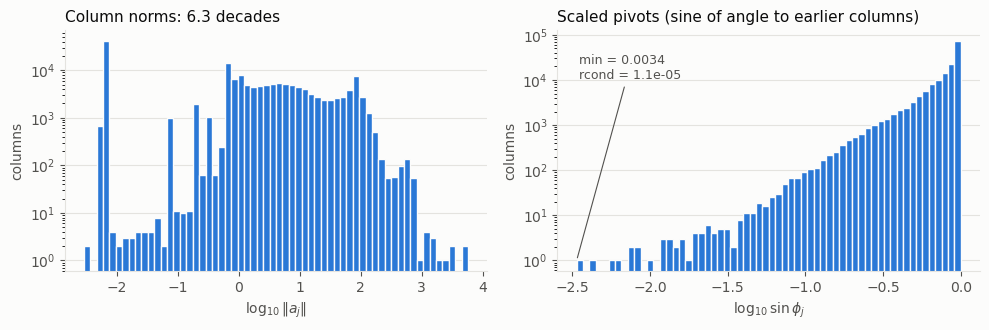

In [8]:
if have_system:
    # one quantity per panel, single hue; light surface, recessive grid and axes
    blue, ink, ink2, surface, grid = '#2a78d6', '#0b0b0b', '#52514e', '#fcfcfb', '#e4e3df'
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), facecolor=surface)
    panels = [(np.log10(norms), r'$\log_{10}\|a_j\|$', f'Column norms: {np.log10(norms.max() / norms.min()):.1f} decades'),
              (np.log10(sin_phi), r'$\log_{10}\sin\phi_j$', 'Scaled pivots (sine of angle to earlier columns)')]
    for ax, (vals, xlabel, title) in zip(axes, panels):
        ax.set_facecolor(surface)
        ax.hist(vals, bins=60, color=blue, edgecolor=surface, linewidth=1)
        ax.set_yscale('log')
        ax.set_xlabel(xlabel, color=ink2)
        ax.set_ylabel('columns', color=ink2)
        ax.set_title(title, color=ink, fontsize=11, loc='left')
        ax.grid(axis='y', color=grid, linewidth=0.8)
        ax.set_axisbelow(True)
        for side in ['top', 'right']:
            ax.spines[side].set_visible(False)
        for side in ['left', 'bottom']:
            ax.spines[side].set_color(grid)
        ax.tick_params(colors=ink2)
    axes[1].annotate(f'min = {sin_phi.min():.4f}\nrcond = {Fs.rcond:.1e}', xy=(np.log10(sin_phi.min()), 1),
                     xytext=(0.05, 0.8), textcoords='axes fraction', color=ink2, fontsize=9,
                     arrowprops=dict(arrowstyle='-', color=ink2, linewidth=0.8))
    fig.tight_layout()
    plt.show()

Left: the column norms span six decades, from about $3\times10^{-3}$ to $6\times10^{3}$.  Since every pivot is at most its column's norm, $\min_j L_{jj} \le \min_j \|a_j\|$, and so $\mathrm{rcond} \le (\min_j\|a_j\| / \max_j L_{jj})^2 = (2.9\times10^{-3} / 1.3\times10^{3})^2 \approx 5\times10^{-12}$ before any dependence between columns is counted.  In the factorization above, the norms of the two extreme pivot columns contribute a factor of about $10^{-11.4}$ to the unscaled `rcond`, and their angles only about $10^{-2.6}$.  The tall bar near $10^{-2.2}$ (about 40,000 columns) is probably the $z_0$ nodes in cells with no data, which only the smoothness constraints touch; the tile has about 54,000 such cells.  This was not checked against the column index of each parameter type.

Right: after scaling, every pivot is the sine of an angle.  Most columns are nearly orthogonal to the span of the columns before them ($\sin\phi_j$ near 1).  The worst is at an angle of about $0.2^\circ$ ($\sin\phi = 0.0034$), which gives `rcond` $= 1.1\times10^{-5}$: nine orders of magnitude above the limit, and an honest measure of how close the fit comes to being singular.

## 9. Measured effect on the fits

These are full `fit_altimetry.py` runs on 2026-10-12: tile E210_N-680 with `RCOND_MIN = 1e-14`, 4 threads, 4 iterations, run two at a time on a 96-core machine.  "Copied" runs repeat the full data set 2/4/8 times, each copy shifted by up to 2 m, to test beyond the data this tile has.

| Run | Points in fit | Iterations kept on CHOLMOD | `rcond` | s / iteration | Total run |
|---|---|---|---|---|---|
| 1×, unscaled | 495k | 2 of 4 | 7e-15 to 1.4e-14 | 25.7 | 2:14 |
| 1×, scaled | 495k | 4 of 4 | 1e-5 to 1.7e-5 | 8.4 | 1:03 |
| all data, unscaled | 1.15M | 0 of 4 | 2e-15 to 4e-15 | 54.4 | 4:17 |
| all data, scaled | 1.15M | 4 of 4 | 1e-6 to 1e-5 | 10.2 | 1:20 |
| copied 2×, scaled | 2.3M | 4 of 4 | 5e-7 to 5e-6 | 12.3 | 1:45 |
| copied 4×, scaled | 4.6M | 4 of 4 | 4e-7 to 2e-6 | 17.6 | 2:46 |
| copied 8×, scaled | 9.2M | 4 of 4 | 1e-7 to 1e-6 | 26.8 | 4:27 |
| E-110_N-3070, scaled | 849k | 4 of 4 | 2e-7 to 5e-6 | 11.5 | 1:12 |

SPQR alone took 35 s per iteration at 1× and 46 s with all the data.  The unscaled runs are slower than SPQR because each fallback first spends about 8 s on a CHOLMOD attempt.

* **Accuracy:** scaled CHOLMOD matched SPQR to about $10^{-10}$ m in $z_0$ (cells with data), $dz$ and the biases, and to $\le 1.3\times10^{-8}$ m in extrapolated $z_0$ cells with no data.  On the copied data, scaled and unscaled CHOLMOD agree to $10^{-10}$ m.
* **Cost:** scaling the stored values of $A^TA$ in place takes 0.1 s per solve, about 1% of the solve.  Building $DND$ with two sparse matrix products took 0.6 s.  Most of that was sorting the row indices, which CHOLMOD otherwise does inside the factorization, so the totals were the same.
* **Cells with no data:** with the 2× and 4× copied data, SPQR and CHOLMOD differ by up to hundreds of metres in about 27,000 extrapolated $z_0$ cells.  These are cells the data don't constrain, almost all with zero cell area.  Where the cell area is nonzero and there are data, the two agree to 0.1 mm (2×) and 0.35 mm (4×), and $dz$ agrees to $2.4\times10^{-5}$ m wherever its cell area is nonzero.  The drift in the unconstrained cells is unimportant.  Scaling doesn't affect it either way, because it doesn't change the CHOLMOD solution.

## 10. Implementation and use

In `LSsurf/ls_solvers.py`, `solve_cholmod(..., scale_columns=True)` does:

```python
N = (AT @ A).tocsc()
N_jj = N.diagonal()
d = 1. / np.sqrt(np.where(N_jj > 0, N_jj, 1.))   # zero columns keep d = 1 (and still fail)
N.data *= d[N.indices]                            # N_ij * d_i   (CSC: indices are rows)
N.data *= np.repeat(d, np.diff(N.indptr))         #      * d_j
...
def solve_N(r):                                   # N^-1 r = D (D N D)^-1 D r
    return d * F.solve(d * r)
x = solve_N(AT @ b)                               # then x += solve_N(AT @ (b - A @ x)) to refine
```

It is opt-in:

* `smooth_fit(..., solver='cholmod', cholmod_scale_columns=True)`
* `fit_altimetry.py ... --cholmod_scale_columns` (CHOLMOD is already the `fit_altimetry.py` default; `--sparseqr` forces SPQR)

The log line reports `column scaling ... s` and `rcond (scaled)`.  Tests are in `tests/test_ls_solvers.py`: badly scaled independent columns are accepted, collinearity still shows in `rcond`, rank-deficient cases still fall back, and a `smooth_fit` with scaling matches SPQR.

## References

* A. van der Sluis (1969), Condition numbers and equilibration of matrices, *Numerische Mathematik* 14, 14–23.
* J. Demmel (1989), On floating point errors in Cholesky, LAPACK Working Note 14.
* N. J. Higham (2002), *Accuracy and Stability of Numerical Algorithms*, 2nd ed., SIAM: ch. 7 (scaling and condition numbers), ch. 8 (triangular systems), ch. 10 (Cholesky), ch. 20 (least squares and the normal equations).
* Å. Björck (1996), *Numerical Methods for Least Squares Problems*, SIAM: the QR–Cholesky relationship and iterative refinement of normal-equation solutions.
* T. A. Davis, CHOLMOD user guide (SuiteSparse): `cholmod_rcond`.